
# 19 — Effective dimensionality of dense context-length probing

Notebooks 11–15 showed that dense context-length probing (CLP)

\[
D_{256}=(L_8,L_9,\ldots,L_{256})
\]

contains substantial redundancy for GPT-vs-Claude source attribution. In particular, six geometrically spaced measurements

\[
G_{256}=(L_8,L_{16},L_{32},L_{64},L_{128},L_{256})
\]

can match dense 249-point probing under several tested settings, while a single endpoint \(L_{256}\) already captures much of the signal.

This notebook asks **why**.

We separate two notions of effective dimension:

1. **Geometric dimension**: how many principal components explain the variance of the dense CLP curve?
2. **Attribution-effective dimension**: how many train-only PCA components are required to recover the source-attribution performance of DenseCLP?

We additionally separate overall loss level from curve shape using the endpoint-normalized curve

\[
S_k = L_k-L_{256},\qquad k=8,\ldots,255.
\]

This lets us test whether dense CLP is low-dimensional merely because documents differ in global surprisal, or whether the **shape of contextual gain itself** is also low-dimensional.

### Important interpretation

PCA here is **representation compression**, not measurement compression. Computing a PCA coordinate still requires the full dense curve at inference time. Therefore PCA cannot replace SL6 operationally; it is used to diagnose the information geometry that may explain why sparse acquisition works.

### Hypotheses

- **H1:** Raw DenseCLP has very low geometric dimension, with PC1 strongly related to \(L_{256}\).
- **H2:** Endpoint-normalized curve shape remains low-dimensional, but may require more components than the raw curve.
- **H3:** \(L_{256}\) plus a small number of train-only shape PCs recovers most DenseCLP attribution performance.
- **H4:** GPT-2 may require more shape dimensions than Qwen3-0.6B, consistent with the scorer-dependent non-inferiority exceptions in notebooks 14–15.


In [1]:
import time

t = time.time()
from pathlib import Path
print("pathlib", time.time() - t)

t = time.time()
import numpy as np
print("numpy", time.time() - t)

t = time.time()
import pandas as pd
print("pandas", time.time() - t)

t = time.time()
import matplotlib.pyplot as plt
print("matplotlib", time.time() - t)

t = time.time()
from sklearn.decomposition import PCA
print("sklearn PCA", time.time() - t)

t = time.time()
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
print("rest sklearn", time.time() - t)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

QWEN_PATH = RESULTS / "cifka_dense_clp_qwen06b.parquet"
GPT2_PATH = RESULTS / "cifka_dense_clp_gpt2.parquet"

assert QWEN_PATH.exists(), QWEN_PATH
assert GPT2_PATH.exists(), GPT2_PATH

MIN_K, MAX_K = 8, 256
DENSE_COLS = [f"L_{k}" for k in range(MIN_K, MAX_K + 1)]
SHAPE_COLS = [f"S_{k}" for k in range(MIN_K, MAX_K)]
SL6_COLS = [f"L_{k}" for k in [8, 16, 32, 64, 128, 256]]

print("ROOT:", ROOT)
print("Dense coordinates:", len(DENSE_COLS))
print("Shape coordinates:", len(SHAPE_COLS))


pathlib 4.076957702636719e-05
numpy 0.09151506423950195
pandas 0.2044074535369873
matplotlib 0.21440482139587402
sklearn PCA 0.7870349884033203
rest sklearn 0.0026476383209228516
ROOT: ..
Dense coordinates: 249
Shape coordinates: 248


In [2]:
def prepare(path, scorer):
    df = pd.read_parquet(path).copy()
    df = df.dropna(subset=DENSE_COLS)

    # Keep only complete GPT/Claude matched pairs.
    pairs = df.groupby("pair_id")["generator"].agg(["size", "nunique"])
    ok = pairs.index[(pairs["size"] == 2) & (pairs["nunique"] == 2)]
    df = df[df["pair_id"].isin(ok)].copy()

    df["label"] = (df["generator"] == "claude").astype(int)
    df["scorer"] = scorer

    # Endpoint-normalized CLP shape:
    # S_k = L_k - L_256, k = 8,...,255
    #
    # Construct all 248 columns at once rather than inserting them
    # individually, which avoids DataFrame fragmentation.
    shape = (
        df[[f"L_{k}" for k in range(MIN_K, MAX_K)]]
        .sub(df["L_256"], axis=0)
    )
    shape.columns = [f"S_{k}" for k in range(MIN_K, MAX_K)]

    df = pd.concat([df, shape], axis=1).copy()

    return df


qwen = prepare(QWEN_PATH, "Qwen3-0.6B")
gpt2 = prepare(GPT2_PATH, "GPT-2")

for name, df in [
    ("Qwen3-0.6B", qwen),
    ("GPT-2", gpt2),
]:
    print(
        name,
        "pairs", df["pair_id"].nunique(),
        "docs", len(df),
    )
    display(df.groupby(["domain", "generator"]).size())


# Both scorers should contain exactly the same matched documents.
q_manifest = set(
    qwen[["pair_id", "generator"]]
    .itertuples(index=False, name=None)
)

g_manifest = set(
    gpt2[["pair_id", "generator"]]
    .itertuples(index=False, name=None)
)

print("same scorer document manifest:", q_manifest == g_manifest)
assert q_manifest == g_manifest

# Sanity checks on shape construction.
assert qwen[SHAPE_COLS].notna().all().all()
assert gpt2[SHAPE_COLS].notna().all().all()

print("shape columns:", len(SHAPE_COLS))

Qwen3-0.6B pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

GPT-2 pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

same scorer document manifest: True
shape columns: 248



## 1. Geometric dimension

PCA is fit here only for **descriptive geometry**. Because every \(L_k\) is measured in the same units, we do not feature-standardize before PCA; otherwise the variance spectrum would describe a rescaled object rather than the actual CLP curve.

We report:

\[
r_\tau = \min\left\{r:\sum_{j=1}^r \mathrm{EVR}_j\ge \tau\right\},
\]

for \(\tau\in\{0.90,0.95,0.99,0.999\}\), and the participation-ratio effective dimension

\[
d_{\mathrm{PR}}=
\frac{\left(\sum_j \lambda_j\right)^2}
     {\sum_j \lambda_j^2}.
\]

For the raw curve we also correlate PC1 with \(L_{256}\). A near-unit correlation would indicate that the leading variance direction is largely an overall-loss axis.


In [3]:

def effective_rank(eigvals):
    eigvals = np.asarray(eigvals, dtype=float)
    return (eigvals.sum() ** 2) / np.square(eigvals).sum()

def threshold_rank(cum_evr, threshold):
    return int(np.searchsorted(cum_evr, threshold) + 1)

geometry_rows = []
spectrum_rows = []
loading_rows = []

for scorer, df in [("Qwen3-0.6B", qwen), ("GPT-2", gpt2)]:
    for representation, cols in [
        ("Raw", DENSE_COLS),
        ("EndpointNormalizedShape", SHAPE_COLS),
    ]:
        X = df[cols].to_numpy(dtype=float)
        pca = PCA()
        Z = pca.fit_transform(X)

        evr = pca.explained_variance_ratio_
        eig = pca.explained_variance_
        cum = np.cumsum(evr)

        row = {
            "scorer": scorer,
            "representation": representation,
            "n_docs": len(df),
            "n_coordinates": len(cols),
            "participation_ratio": effective_rank(eig),
            "r90": threshold_rank(cum, 0.90),
            "r95": threshold_rank(cum, 0.95),
            "r99": threshold_rank(cum, 0.99),
            "r999": threshold_rank(cum, 0.999),
        }

        if representation == "Raw":
            row["pc1_corr_L256"] = np.corrcoef(Z[:, 0], df["L_256"].to_numpy())[0, 1]
        else:
            row["pc1_corr_L256"] = np.nan

        geometry_rows.append(row)

        for j, (v, c) in enumerate(zip(evr, cum), start=1):
            spectrum_rows.append({
                "scorer": scorer,
                "representation": representation,
                "pc": j,
                "evr": v,
                "cumulative_evr": c,
            })

        # Save the first three loading curves for interpretation.
        for pc_idx in range(min(3, pca.components_.shape[0])):
            for col, loading in zip(cols, pca.components_[pc_idx]):
                k = int(col.split("_")[1])
                loading_rows.append({
                    "scorer": scorer,
                    "representation": representation,
                    "pc": pc_idx + 1,
                    "k": k,
                    "loading": loading,
                })

geometry = pd.DataFrame(geometry_rows)
spectrum = pd.DataFrame(spectrum_rows)
loadings = pd.DataFrame(loading_rows)

geometry.to_csv(RESULTS / "clp_effective_dimensionality_geometry.csv", index=False)
spectrum.to_csv(RESULTS / "clp_effective_dimensionality_spectrum.csv", index=False)
loadings.to_csv(RESULTS / "clp_effective_dimensionality_loadings.csv", index=False)

display(geometry)


,scorer,representation,n_docs,n_coordinates,participation_ratio,r90,r95,r99,r999,pc1_corr_L256
0,Qwen3-0.6B,Raw,292,249,1.078199,1,1,3,16,0.983988
1,Qwen3-0.6B,EndpointNormalizedShape,292,248,1.850152,3,6,20,85,NaN
2,GPT-2,Raw,292,249,1.130509,1,2,4,19,0.973383
3,GPT-2,EndpointNormalizedShape,292,248,1.726089,3,5,17,74,NaN


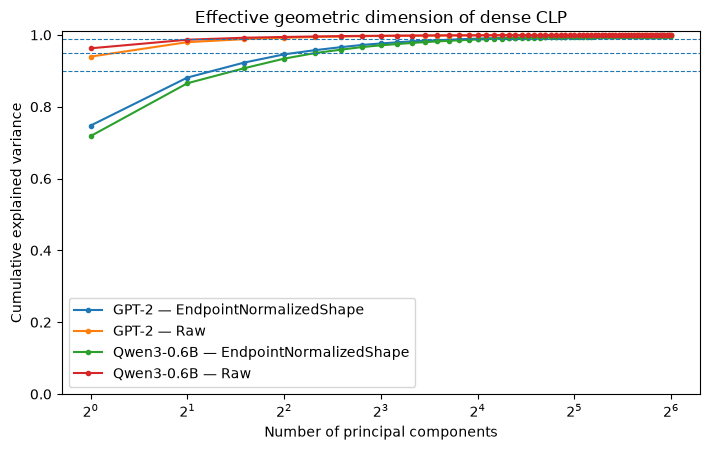

In [4]:

# Cumulative explained-variance figure.
fig, ax = plt.subplots(figsize=(7.2, 4.6))

for (scorer, rep), g in spectrum.groupby(["scorer", "representation"]):
    g = g[g["pc"] <= 64]
    ax.plot(g["pc"], g["cumulative_evr"], marker="o", markersize=3,
            label=f"{scorer} — {rep}")

for y in [0.90, 0.95, 0.99]:
    ax.axhline(y, linestyle="--", linewidth=0.8)

ax.set_xscale("log", base=2)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("Effective geometric dimension of dense CLP")
ax.set_ylim(0, 1.01)
ax.legend()
fig.tight_layout()

fig.savefig(FIGURES / "clp_effective_dimension_spectrum.png", dpi=220, bbox_inches="tight")
fig.savefig(FIGURES / "clp_effective_dimension_spectrum.pdf", bbox_inches="tight")
plt.show()


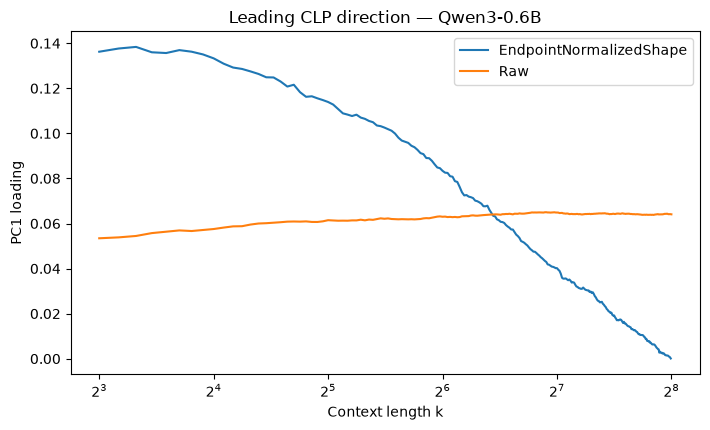

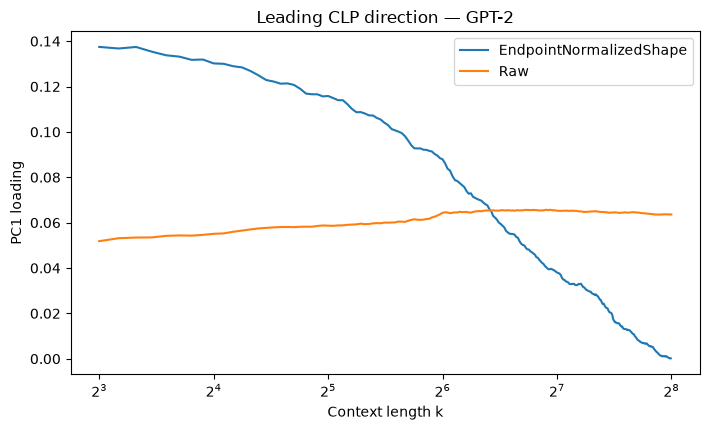

In [5]:

# First-PC loading curves: useful for checking whether the leading raw PC
# is approximately a global level shift and what the leading shape PC represents.
for scorer in ["Qwen3-0.6B", "GPT-2"]:
    fig, ax = plt.subplots(figsize=(7.2, 4.4))

    sub = loadings[
        (loadings["scorer"] == scorer) &
        (loadings["pc"] == 1)
    ]

    for rep, g in sub.groupby("representation"):
        ax.plot(g["k"], g["loading"], label=rep)

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Context length k")
    ax.set_ylabel("PC1 loading")
    ax.set_title(f"Leading CLP direction — {scorer}")
    ax.legend()
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(FIGURES / f"clp_pc1_loading_{stem}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"clp_pc1_loading_{stem}.pdf", bbox_inches="tight")
    plt.show()



## 2. Attribution-effective dimension with strictly train-only PCA

We now evaluate whether a low-dimensional PCA representation preserves GPT-vs-Claude attribution.

The outer protocol exactly follows notebook 13:

- 20 seeded source-pair splits;
- 80/20 split at the `pair_id` level;
- both documents from a matched GPT/Claude pair remain together;
- logistic-regression \(C\) is selected by grouped cross-validation **inside the outer training set**.

Crucially, PCA itself is part of the sklearn pipeline. Therefore every inner validation fold and every outer test fold is transformed by a PCA basis fit **only on its corresponding training data**.

We compare:

- `L256`: the single endpoint;
- `SL6`: six geometrically spaced measured losses;
- `Dense`: all 249 measured losses;
- `RawPC(r)`: \(r\) PCs of the full dense curve;
- `ShapePC(r)`: \(r\) PCs of \(S_k=L_k-L_{256}\);
- `L256+ShapePC(r)`: endpoint level plus \(r\) train-only shape PCs.

The last representation most directly asks how many additional shape dimensions are useful **after the strong endpoint baseline is already known**.


In [6]:

C_GRID = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
R_GRID = [1, 2, 3, 4, 6, 8, 16, 32, 64, 128]

def logistic(C):
    return LogisticRegression(
        C=C,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=5000,
        random_state=0,
    )


def make_model(kind, C, r=None):

    if kind == "L256":
        features = ColumnTransformer([
            ("endpoint", StandardScaler(), ["L_256"]),
        ])

    elif kind == "SL6":
        features = ColumnTransformer([
            ("sl6", StandardScaler(), SL6_COLS),
        ])

    elif kind == "Dense":
        # Notebook-13-compatible dense baseline.
        features = ColumnTransformer([
            ("dense", StandardScaler(), DENSE_COLS),
        ])

    elif kind == "RawPC":
        assert r is not None

        # Standardize the original CLP coordinates FIRST,
        # then perform train-only PCA.
        #
        # Do NOT standardize PCs afterward: doing so would
        # amplify low-variance/noisy PCs as r increases.
        features = ColumnTransformer([
            ("rawpc", Pipeline([
                ("scale", StandardScaler()),
                ("pca", PCA(
                    n_components=r,
                    svd_solver="full",
                )),
            ]), DENSE_COLS),
        ])

    elif kind == "ShapePC":
        assert r is not None

        features = ColumnTransformer([
            ("shapepc", Pipeline([
                ("scale", StandardScaler()),
                ("pca", PCA(
                    n_components=r,
                    svd_solver="full",
                )),
            ]), SHAPE_COLS),
        ])

    elif kind == "L256+ShapePC":
        assert r is not None

        features = ColumnTransformer([
            ("endpoint", StandardScaler(), ["L_256"]),

            ("shape", Pipeline([
                ("scale", StandardScaler()),
                ("pca", PCA(
                    n_components=r,
                    svd_solver="full",
                )),
            ]), SHAPE_COLS),
        ])

    else:
        raise ValueError(kind)

    return Pipeline([
        ("features", features),
        ("clf", logistic(C)),
    ])


def choose_C(tr, kind, r=None):
    y = tr["label"].to_numpy()
    groups = tr["pair_id"].to_numpy()
    cv = GroupKFold(n_splits=min(5, tr["pair_id"].nunique()))

    vals = []
    for C in C_GRID:
        aucs = []
        for ti, vi in cv.split(tr, y, groups=groups):
            model = make_model(kind, C, r)
            model.fit(tr.iloc[ti], y[ti])
            p = model.predict_proba(tr.iloc[vi])[:, 1]
            aucs.append(roc_auc_score(y[vi], p))
        vals.append((np.mean(aucs), C))

    vals.sort(key=lambda z: (-z[0], z[1]))
    return vals[0][1]


# Sanity-check that every requested r is feasible inside the smallest
# approximate inner-training fold.
n_outer_train_docs = int(0.8 * qwen["pair_id"].nunique()) * 2
n_inner_train_docs_approx = int(0.8 * n_outer_train_docs)
print("Approx outer-train docs:", n_outer_train_docs)
print("Approx smallest inner-train docs:", n_inner_train_docs_approx)
print("Max requested r:", max(R_GRID))
assert max(R_GRID) < n_inner_train_docs_approx


Approx outer-train docs: 232
Approx smallest inner-train docs: 185
Max requested r: 128


In [7]:

def eval_effective_dimension(df, scorer):
    ids = np.array(sorted(df["pair_id"].unique()))
    rows = []

    for seed in range(20):
        rng = np.random.RandomState(seed)
        perm = rng.permutation(len(ids))
        cut = int(0.8 * len(ids))
        tr_ids = set(ids[perm[:cut]])
        te_ids = set(ids[perm[cut:]])

        tr = df[df["pair_id"].isin(tr_ids)].copy()
        te = df[df["pair_id"].isin(te_ids)].copy()

        # Fixed baselines, evaluated once per seed.
        for kind in ["L256", "SL6", "Dense"]:
            C = choose_C(tr, kind)
            model = make_model(kind, C)
            model.fit(tr, tr["label"])
            p = model.predict_proba(te)[:, 1]
            rows.append({
                "scorer": scorer,
                "seed": seed,
                "kind": kind,
                "r": np.nan,
                "best_C": C,
                "auroc": roc_auc_score(te["label"], p),
            })

        # Learned low-dimensional representations.
        for r in R_GRID:
            for kind in ["RawPC", "ShapePC", "L256+ShapePC"]:
                C = choose_C(tr, kind, r)
                model = make_model(kind, C, r)
                model.fit(tr, tr["label"])
                p = model.predict_proba(te)[:, 1]
                rows.append({
                    "scorer": scorer,
                    "seed": seed,
                    "kind": kind,
                    "r": r,
                    "best_C": C,
                    "auroc": roc_auc_score(te["label"], p),
                })

        print(scorer, "finished seed", seed)

    return pd.DataFrame(rows)


effective_splits = pd.concat([
    eval_effective_dimension(qwen, "Qwen3-0.6B"),
    eval_effective_dimension(gpt2, "GPT-2"),
], ignore_index=True)

effective_splits.to_csv(
    RESULTS / "clp_effective_dimensionality_splits.csv",
    index=False
)

print("rows:", len(effective_splits))
display(effective_splits.head())


Qwen3-0.6B finished seed 0
Qwen3-0.6B finished seed 1
Qwen3-0.6B finished seed 2
Qwen3-0.6B finished seed 3
Qwen3-0.6B finished seed 4
Qwen3-0.6B finished seed 5
Qwen3-0.6B finished seed 6
Qwen3-0.6B finished seed 7
Qwen3-0.6B finished seed 8
Qwen3-0.6B finished seed 9
Qwen3-0.6B finished seed 10
Qwen3-0.6B finished seed 11
Qwen3-0.6B finished seed 12
Qwen3-0.6B finished seed 13
Qwen3-0.6B finished seed 14
Qwen3-0.6B finished seed 15
Qwen3-0.6B finished seed 16
Qwen3-0.6B finished seed 17
Qwen3-0.6B finished seed 18
Qwen3-0.6B finished seed 19
GPT-2 finished seed 0
GPT-2 finished seed 1
GPT-2 finished seed 2
GPT-2 finished seed 3
GPT-2 finished seed 4
GPT-2 finished seed 5
GPT-2 finished seed 6
GPT-2 finished seed 7
GPT-2 finished seed 8
GPT-2 finished seed 9
GPT-2 finished seed 10
GPT-2 finished seed 11
GPT-2 finished seed 12
GPT-2 finished seed 13
GPT-2 finished seed 14
GPT-2 finished seed 15
GPT-2 finished seed 16
GPT-2 finished seed 17
GPT-2 finished seed 18
GPT-2 finished seed 19


,scorer,seed,kind,r,best_C,auroc
0,Qwen3-0.6B,0,L256,NaN,0.001,0.915556
1,Qwen3-0.6B,0,SL6,NaN,1.000,0.936667
2,Qwen3-0.6B,0,Dense,NaN,0.001,0.918889
3,Qwen3-0.6B,0,RawPC,1.0,0.001,0.915556
4,Qwen3-0.6B,0,ShapePC,1.0,0.001,0.507778


In [8]:

# Aggregate without pretending the 20 overlapping splits are independent replications.
baseline = (
    effective_splits[effective_splits["kind"].isin(["L256", "SL6", "Dense"])]
    .groupby(["scorer", "kind"])["auroc"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

pc_summary = (
    effective_splits[effective_splits["kind"].isin(["RawPC", "ShapePC", "L256+ShapePC"])]
    .groupby(["scorer", "kind", "r"])["auroc"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

dense_by_seed = (
    effective_splits[effective_splits["kind"] == "Dense"]
    [["scorer", "seed", "auroc"]]
    .rename(columns={"auroc": "dense_auroc"})
)

l256_by_seed = (
    effective_splits[effective_splits["kind"] == "L256"]
    [["scorer", "seed", "auroc"]]
    .rename(columns={"auroc": "l256_auroc"})
)

paired = (
    effective_splits[
        effective_splits["kind"].isin(["RawPC", "ShapePC", "L256+ShapePC"])
    ]
    .merge(dense_by_seed, on=["scorer", "seed"], how="left")
    .merge(l256_by_seed, on=["scorer", "seed"], how="left")
)

paired["delta_vs_dense"] = paired["auroc"] - paired["dense_auroc"]
paired["delta_vs_L256"] = paired["auroc"] - paired["l256_auroc"]

paired_summary = (
    paired.groupby(["scorer", "kind", "r"])
    .agg(
        mean_auroc=("auroc", "mean"),
        mean_delta_vs_dense=("delta_vs_dense", "mean"),
        median_delta_vs_dense=("delta_vs_dense", "median"),
        positive_vs_dense=("delta_vs_dense", lambda x: int((x > 0).sum())),
        mean_delta_vs_L256=("delta_vs_L256", "mean"),
        positive_vs_L256=("delta_vs_L256", lambda x: int((x > 0).sum())),
    )
    .reset_index()
)

baseline.to_csv(
    RESULTS / "clp_effective_dimensionality_baselines.csv",
    index=False
)
paired_summary.to_csv(
    RESULTS / "clp_effective_dimensionality_summary.csv",
    index=False
)

print("Baselines")
display(baseline)

print("PCA summary")
display(paired_summary)


Baselines


,scorer,kind,mean,median,min,max
0,GPT-2,Dense,0.751222,0.747222,0.626667,0.902222
1,GPT-2,L256,0.745444,0.758333,0.646667,0.850000
2,GPT-2,SL6,0.744167,0.747222,0.634444,0.878889
3,Qwen3-0.6B,Dense,0.850889,0.857222,0.761111,0.934444
4,Qwen3-0.6B,L256,0.848167,0.851667,0.781111,0.924444
5,Qwen3-0.6B,SL6,0.866722,0.873889,0.787778,0.945556


PCA summary


,scorer,kind,r,mean_auroc,mean_delta_vs_dense,median_delta_vs_dense,positive_vs_dense,mean_delta_vs_L256,positive_vs_L256
0,GPT-2,L256+ShapePC,1.0,0.741944,-0.009278,-0.011667,8,-0.003500,4
1,GPT-2,L256+ShapePC,2.0,0.738778,-0.012444,-0.018889,6,-0.006667,10
2,GPT-2,L256+ShapePC,3.0,0.732444,-0.018778,-0.024444,5,-0.013000,7
3,GPT-2,L256+ShapePC,4.0,0.725833,-0.025389,-0.024444,3,-0.019611,7
4,GPT-2,L256+ShapePC,6.0,0.728444,-0.022778,-0.026667,4,-0.017000,7
5,GPT-2,L256+ShapePC,8.0,0.744667,-0.006556,-0.008333,5,-0.000778,11
6,GPT-2,L256+ShapePC,16.0,0.722111,-0.029111,-0.020000,5,-0.023333,6
7,GPT-2,L256+ShapePC,32.0,0.710889,-0.040333,-0.041111,5,-0.034556,6
8,GPT-2,L256+ShapePC,64.0,0.712667,-0.038556,-0.034444,6,-0.032778,7
9,GPT-2,L256+ShapePC,128.0,0.711000,-0.040222,-0.025556,5,-0.034444,6


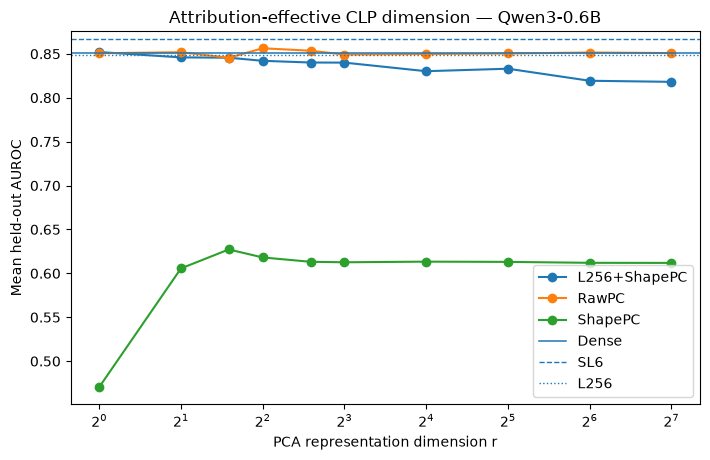

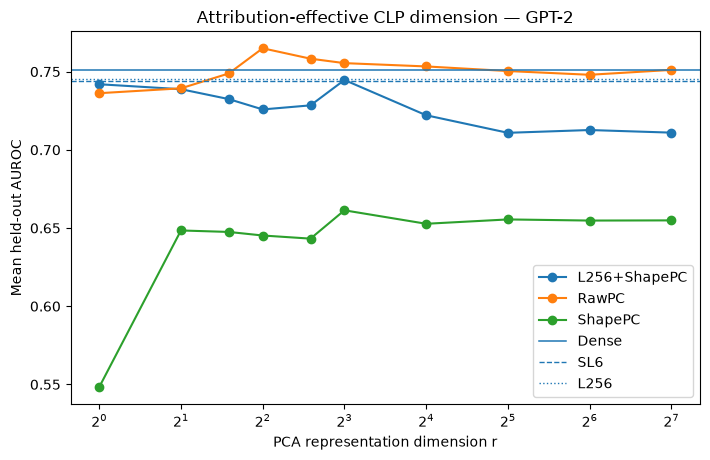

In [9]:

# AUROC as representation dimension increases.
for scorer in ["Qwen3-0.6B", "GPT-2"]:
    fig, ax = plt.subplots(figsize=(7.2, 4.7))

    s = paired_summary[paired_summary["scorer"] == scorer]
    for kind, g in s.groupby("kind"):
        ax.plot(g["r"], g["mean_auroc"], marker="o", label=kind)

    b = baseline[baseline["scorer"] == scorer].set_index("kind")["mean"]
    ax.axhline(b["Dense"], linestyle="-", linewidth=1.1, label="Dense")
    ax.axhline(b["SL6"], linestyle="--", linewidth=1.0, label="SL6")
    ax.axhline(b["L256"], linestyle=":", linewidth=1.0, label="L256")

    ax.set_xscale("log", base=2)
    ax.set_xlabel("PCA representation dimension r")
    ax.set_ylabel("Mean held-out AUROC")
    ax.set_title(f"Attribution-effective CLP dimension — {scorer}")
    ax.legend()
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(
        FIGURES / f"clp_effective_dimension_attribution_{stem}.png",
        dpi=220, bbox_inches="tight"
    )
    fig.savefig(
        FIGURES / f"clp_effective_dimension_attribution_{stem}.pdf",
        bbox_inches="tight"
    )
    plt.show()


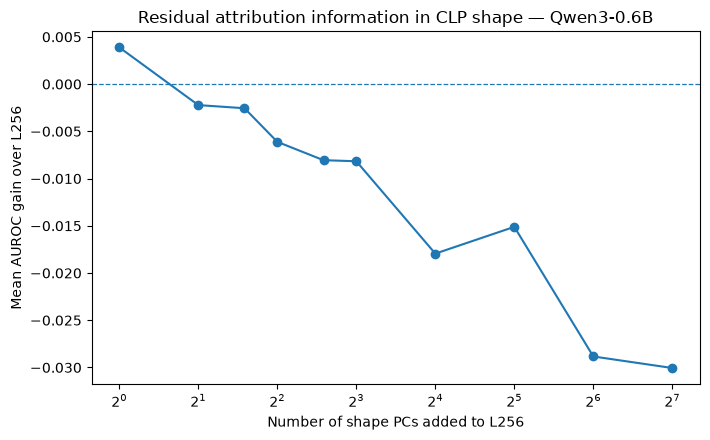

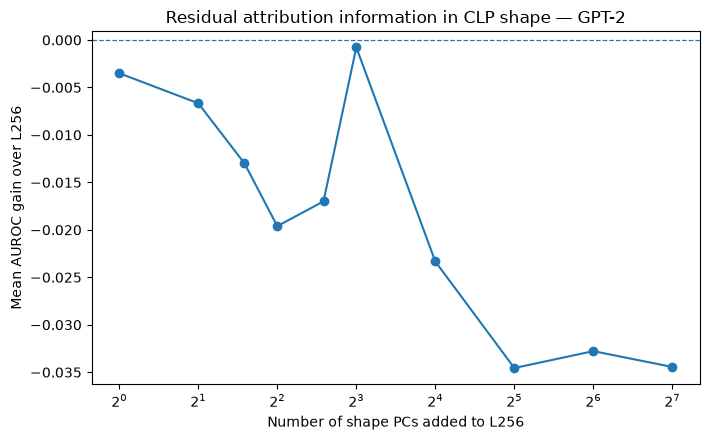

In [10]:

# Focused diagnostic: how much does train-only curve shape add after L256?
for scorer in ["Qwen3-0.6B", "GPT-2"]:
    fig, ax = plt.subplots(figsize=(7.2, 4.5))

    s = paired_summary[
        (paired_summary["scorer"] == scorer) &
        (paired_summary["kind"] == "L256+ShapePC")
    ]

    ax.plot(s["r"], s["mean_delta_vs_L256"], marker="o")
    ax.axhline(0, linestyle="--", linewidth=0.9)

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Number of shape PCs added to L256")
    ax.set_ylabel("Mean AUROC gain over L256")
    ax.set_title(f"Residual attribution information in CLP shape — {scorer}")
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(
        FIGURES / f"clp_shape_pc_gain_over_L256_{stem}.png",
        dpi=220, bbox_inches="tight"
    )
    fig.savefig(
        FIGURES / f"clp_shape_pc_gain_over_L256_{stem}.pdf",
        bbox_inches="tight"
    )
    plt.show()


In [11]:
DELTA = 0.01
BOOT = 20000
RNG_SEED = 1901

def paired_bootstrap_ci(x, n_boot=BOOT, seed=RNG_SEED):
    x = np.asarray(x, dtype=float)
    rng = np.random.RandomState(seed)

    means = np.empty(n_boot)
    for b in range(n_boot):
        sample = rng.choice(x, size=len(x), replace=True)
        means[b] = sample.mean()

    return (
        np.quantile(means, 0.025),
        np.quantile(means, 0.975),
    )


rows = []

for scorer in sorted(paired["scorer"].unique()):
    for kind in ["RawPC", "L256+ShapePC"]:
        sub = paired[
            (paired["scorer"] == scorer) &
            (paired["kind"] == kind)
        ]

        for r in sorted(sub["r"].unique()):
            x = sub.loc[sub["r"] == r, "delta_vs_dense"].to_numpy()

            lo, hi = paired_bootstrap_ci(
                x,
                seed=RNG_SEED + int(r)
            )

            rows.append({
                "scorer": scorer,
                "kind": kind,
                "r": int(r),
                "mean_delta": x.mean(),
                "median_delta": np.median(x),
                "ci_low": lo,
                "ci_high": hi,
                "noninferior_delta_001": lo > -DELTA,
                "positive_splits": int((x > 0).sum()),
                "n": len(x),
            })

pca_noninf = pd.DataFrame(rows)

pca_noninf.to_csv(
    RESULTS / "clp_effective_dimensionality_noninferiority.csv",
    index=False
)

display(pca_noninf)

,scorer,kind,r,mean_delta,median_delta,ci_low,ci_high,noninferior_delta_001,positive_splits,n
0,GPT-2,RawPC,1,-0.015000,-0.015000,-0.027667,-0.002167,False,6,20
1,GPT-2,RawPC,2,-0.011889,-0.016111,-0.024278,0.001333,False,6,20
2,GPT-2,RawPC,3,-0.002389,-0.001667,-0.012222,0.008500,False,9,20
3,GPT-2,RawPC,4,0.013722,0.008889,0.005222,0.022833,True,14,20
4,GPT-2,RawPC,6,0.007056,0.005000,-0.000611,0.015056,True,14,20
5,GPT-2,RawPC,8,0.004222,0.000556,-0.002056,0.011556,True,10,20
6,GPT-2,RawPC,16,0.002111,0.000000,-0.004444,0.009667,True,5,20
7,GPT-2,RawPC,32,-0.000833,0.000000,-0.006556,0.004556,True,7,20
8,GPT-2,RawPC,64,-0.003222,0.000000,-0.007667,-0.000222,True,2,20
9,GPT-2,RawPC,128,-0.000111,0.000000,-0.000500,0.000278,True,2,20


In [12]:
raw = pca_noninf[pca_noninf["kind"] == "RawPC"].copy()

for scorer in raw["scorer"].unique():
    s = raw[raw["scorer"] == scorer]

    passing = s[s["noninferior_delta_001"]]

    print("\n", scorer)

    if len(passing):
        first = passing.sort_values("r").iloc[0]
        print(
            "smallest non-inferior r:",
            int(first["r"]),
            "| mean Δ:",
            round(first["mean_delta"], 4),
            "| 95% CI:",
            (
                round(first["ci_low"], 4),
                round(first["ci_high"], 4),
            ),
        )
    else:
        print("No tested r passes δ = 0.01")


 GPT-2
smallest non-inferior r: 4 | mean Δ: 0.0137 | 95% CI: (np.float64(0.0052), np.float64(0.0228))

 Qwen3-0.6B
smallest non-inferior r: 2 | mean Δ: 0.0009 | 95% CI: (np.float64(-0.0059), np.float64(0.0084))


In [13]:
raw = (
    pca_noninf[pca_noninf["kind"] == "RawPC"]
    .sort_values(["scorer", "r"])
    .copy()
)

rows = []

for scorer, s in raw.groupby("scorer"):
    s = s.sort_values("r").reset_index(drop=True)

    stable_r = None

    for i in range(len(s)):
        # Smallest r such that this r and every larger tested r
        # satisfy the primary non-inferiority criterion.
        if s.loc[i:, "noninferior_delta_001"].all():
            stable_r = int(s.loc[i, "r"])
            break

    rows.append({
        "scorer": scorer,
        "stable_noninferior_r": stable_r,
    })

stable_dim = pd.DataFrame(rows)

stable_dim.to_csv(
    RESULTS / "clp_effective_dimensionality_stable_r.csv",
    index=False
)

display(stable_dim)

,scorer,stable_noninferior_r
0,GPT-2,4
1,Qwen3-0.6B,4


In [14]:
from sklearn.preprocessing import StandardScaler

rows = []

for scorer, df in [
    ("Qwen3-0.6B", qwen),
    ("GPT-2", gpt2),
]:
    X = StandardScaler().fit_transform(df[DENSE_COLS])

    pca = PCA().fit(X)

    evr = pca.explained_variance_ratio_
    cum = np.cumsum(evr)
    eig = pca.explained_variance_

    rows.append({
        "scorer": scorer,
        "participation_ratio":
            (eig.sum() ** 2) / np.square(eig).sum(),

        "r90": np.searchsorted(cum, 0.90) + 1,
        "r95": np.searchsorted(cum, 0.95) + 1,
        "r99": np.searchsorted(cum, 0.99) + 1,
    })

standardized_geometry = pd.DataFrame(rows)

standardized_geometry.to_csv(
    RESULTS / "clp_effective_dimensionality_standardized_geometry.csv",
    index=False
)

display(standardized_geometry)

,scorer,participation_ratio,r90,r95,r99
0,Qwen3-0.6B,1.079361,1,1,3
1,GPT-2,1.132450,1,2,4


In [15]:
# Matched-pair bootstrap uncertainty for participation-ratio dimension.
#
# Requires qwen, gpt2, and DENSE_COLS from notebook 19.
# Resamples pair_id, never individual documents.

N_BOOT = 5000
BOOT_SEED = 1919

# Use the same bootstrap pair-count draws for both scorers.
pair_ids = np.array(sorted(qwen["pair_id"].unique()))
assert pair_ids.tolist() == sorted(gpt2["pair_id"].unique())

P = len(pair_ids)

rng = np.random.RandomState(BOOT_SEED)

# Each row gives the number of times each matched pair is drawn.
pair_counts = rng.multinomial(
    P,
    np.full(P, 1.0 / P),
    size=N_BOOT,
).astype(float)


def pr_from_centered(X):
    X = np.asarray(X, dtype=float)
    Xc = X - X.mean(axis=0, keepdims=True)

    # Scale of covariance cancels in participation ratio.
    C = Xc.T @ Xc

    return (
        np.trace(C) ** 2
        / np.square(C).sum()
    )


def bootstrap_pr(df, scorer):
    df = df.reset_index(drop=True).copy()

    # Every matched pair must contribute exactly two documents.
    counts = df.groupby("pair_id").size()
    assert (counts == 2).all()

    pair_index = {
        pid: i
        for i, pid in enumerate(pair_ids)
    }

    doc_pair_index = np.array([
        pair_index[pid]
        for pid in df["pair_id"]
    ])

    # B x n_docs bootstrap weights.
    # A pair drawn c times gives weight c to both documents.
    W = pair_counts[:, doc_pair_index]

    L = df[DENSE_COLS].to_numpy(dtype=float)

    reps = {
        "RawL": L,

        # Endpoint-normalized shape.
        "Shape": (
            L[:, :-1]
            - L[:, [-1]]
        ),

        # Adjacent marginal context gain.
        "Marginal": (
            L[:, :-1]
            - L[:, 1:]
        ),
    }

    rows = []
    replicate_rows = []

    for representation, X in reps.items():

        # Point estimate on the original sample.
        point = pr_from_centered(X)

        # Precompute document Gram matrix.
        #
        # The participation ratio of the weighted centered
        # covariance can be computed without forming a
        # p x p covariance matrix for every bootstrap draw.
        G = X @ X.T
        H = G * G
        diag_G = np.diag(G)

        # Number of weighted document observations.
        n = W.sum(axis=1)

        # A = X^T W X
        # s = X^T w
        #
        # tr(A)
        trace_A = W @ diag_G

        # ||s||^2 = w^T G w
        WG = W @ G
        s2 = np.sum(WG * W, axis=1)

        # ||A||_F^2 = w^T (G ⊙ G) w
        WH = W @ H
        A_frob2 = np.sum(WH * W, axis=1)

        # s^T A s
        sAs = np.sum(
            W * np.square(WG),
            axis=1,
        )

        # Centered scatter:
        #
        # C = A - ss^T / n
        trace_C = trace_A - s2 / n

        C_frob2 = (
            A_frob2
            - 2.0 * sAs / n
            + np.square(s2) / np.square(n)
        )

        boot_pr = (
            np.square(trace_C)
            / C_frob2
        )

        lo, hi = np.quantile(
            boot_pr,
            [0.025, 0.975],
        )

        rows.append({
            "scorer": scorer,
            "representation": representation,
            "dPR": point,
            "ci_low": lo,
            "ci_high": hi,
            "bootstrap_median": np.median(boot_pr),
            "n_pairs": P,
            "n_boot": N_BOOT,
        })

        replicate_rows.extend({
            "scorer": scorer,
            "representation": representation,
            "boot": b,
            "dPR": value,
        } for b, value in enumerate(boot_pr))

    return (
        pd.DataFrame(rows),
        pd.DataFrame(replicate_rows),
    )


q_summary, q_boot = bootstrap_pr(
    qwen,
    "Qwen3-0.6B",
)

g_summary, g_boot = bootstrap_pr(
    gpt2,
    "GPT-2",
)

dpr_bootstrap_summary = pd.concat(
    [q_summary, g_summary],
    ignore_index=True,
)

dpr_bootstrap_replicates = pd.concat(
    [q_boot, g_boot],
    ignore_index=True,
)

dpr_bootstrap_summary.to_csv(
    RESULTS / "clp_effective_dimensionality_bootstrap_summary.csv",
    index=False,
)

dpr_bootstrap_replicates.to_csv(
    RESULTS / "clp_effective_dimensionality_bootstrap_replicates.csv",
    index=False,
)

display(dpr_bootstrap_summary)

,scorer,representation,dPR,ci_low,ci_high,bootstrap_median,n_pairs,n_boot
0,Qwen3-0.6B,RawL,1.078199,1.064361,1.094543,1.077958,146,5000
1,Qwen3-0.6B,Shape,1.850152,1.696058,2.031078,1.845624,146,5000
2,Qwen3-0.6B,Marginal,50.397899,32.459748,46.115162,41.687923,146,5000
3,GPT-2,RawL,1.130509,1.103543,1.163000,1.129573,146,5000
4,GPT-2,Shape,1.726089,1.594458,1.874606,1.716226,146,5000
5,GPT-2,Marginal,59.508042,38.230719,52.218670,46.282542,146,5000



## Interpretation checklist

Do **not** collapse the following into one claim.

### A. Geometric low rank
If raw DenseCLP reaches high explained variance with very few PCs, then the 249-dimensional curve lies near a low-dimensional linear subspace in the tested sample.

### B. Level versus shape
If raw PC1 is strongly correlated with \(L_{256}\), then much of the raw low-rank structure is an overall-loss axis. The endpoint-normalized PCA tells us whether context-response **shape** is itself low-dimensional.

### C. Attribution-effective rank
If `RawPC(r)` or `L256+ShapePC(r)` reaches DenseCLP AUROC for small \(r\), then only a few learned directions are needed to preserve the attribution-relevant information in the already-measured dense curve.

### D. Measurement efficiency remains a separate result
Even a one-dimensional PCA representation still requires computing all 249 dense \(L_k\) values. The operational measurement-efficiency result remains notebooks 13–15: sparse geometric acquisition can avoid computing most context lengths in the first place.

### E. Scorer heterogeneity is scientifically useful
If GPT-2 requires more PCs or retains more residual shape information than Qwen, that offers a plausible geometric explanation for why GPT-2 showed non-inferiority failures at larger \(N\). If the effective dimensions are similar, then the earlier scorer difference is more likely due to which directions are discriminatively useful rather than simple rank.


## Conclusion

Dense context-length probing is strongly low-dimensional under both tested scorers.

For the raw 249-coordinate profile \(D_{256}=(L_8,\ldots,L_{256})\),
the participation-ratio effective dimension is 1.08 for Qwen3-0.6B
and 1.13 for GPT-2. One principal component explains at least 90% of
variance for both scorers; 99% is reached with 3 PCs for Qwen and
4 PCs for GPT-2. The leading raw PC is strongly correlated with
\(L_{256}\) (\(r=0.984\) and \(0.973\)), showing that the dominant
direction is largely an overall predictive-loss axis.

After removing the endpoint level via

\[
S_k=L_k-L_{256},
\]

the response shape remains low-dimensional: participation ratios are
1.85 for Qwen and 1.73 for GPT-2, with 95% of shape variance captured
by 6 and 5 PCs respectively.

In train-only PCA attribution experiments, a stable practical
non-inferiority threshold of \(r=4\) is obtained for both scorers
relative to the full 249-dimensional DenseCLP representation under
the primary \(\delta=0.01\) AUROC criterion.

Thus the dense CLP curve contains substantial representational
redundancy: approximately four learned directions recover its
attribution-relevant information, while notebooks 13--15 separately
show that six logarithmically spaced *measured* context lengths can
often recover dense-profile performance without acquiring the full
curve.

These results distinguish representation compression from acquisition
compression. PCA explains why DenseCLP is redundant but still requires
all 249 measurements; geometric probing converts that redundancy into
measurement savings.

Finally, GPT-2 is not geometrically higher-dimensional than Qwen,
despite its larger-range failures of fixed geometric probing.
Therefore scorer-dependent sparse-probing performance appears to
depend on alignment between the chosen context grid and discriminative
directions, rather than intrinsic rank alone.

In [16]:
print("test")

test
